<h1><center>Module 2 : Stationnarité et Outils Mathématiques

In [7]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt

from statsmodels.tsa.stattools import adfuller
from scipy.stats import boxcox

In [8]:
# Définir un jeu de donnée fictif
np.random.seed(42)

n = 120
time = np.arange(n)
trend = 0.3 * (time** 1.4)
noise = np.random.normal(0, 1, n) * (time + 1) * 0.15
series = 20 + trend + noise

dates = pd.date_range(start= "2016-01-01", periods= n, freq= "ME")
df = pd.DataFrame({"Ventes": series}, index= dates)

df

,Ventes
2016-01-31,20.074507
2016-02-29,20.258521
2016-03-31,21.083165
2016-04-30,22.310479
2016-05-31,21.913706
...,...
2025-08-31,255.443167
2025-09-30,252.394306
2025-10-31,235.134847
2025-11-30,279.046434


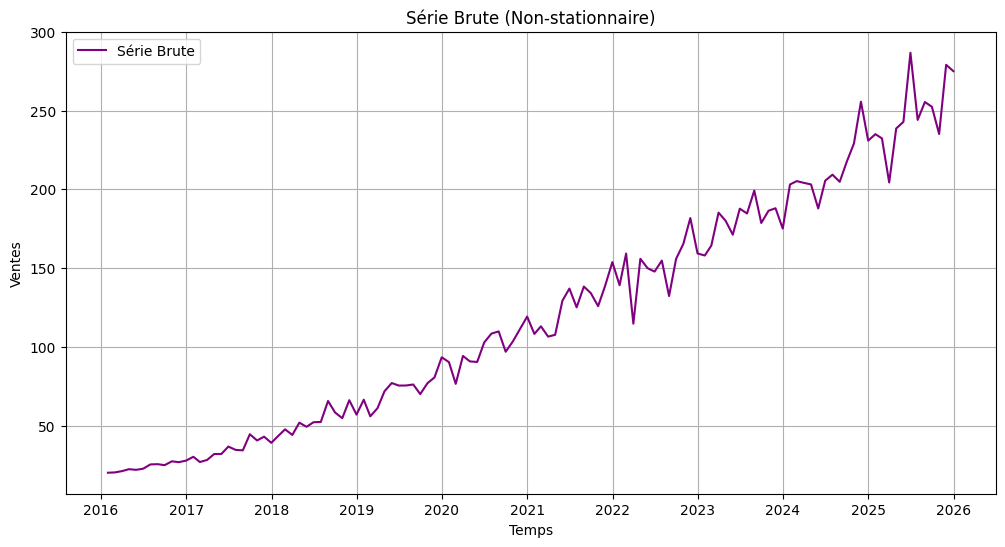

In [9]:
# visualization de la série

plt.figure(figsize=(12,6))
plt.plot(df.index, df['Ventes'], color="purple", label="Série Brute")
plt.title("Série Brute (Non-stationnaire)")
plt.xlabel("Temps")
plt.ylabel("Ventes")
plt.legend()
plt.grid(True)
plt.show()

### Méthode 1: Les statistiques glissantes

<b> - Une série stationnaire si : </b>
- Sa moyenne, variance, autocovariance est constante au fil du temps

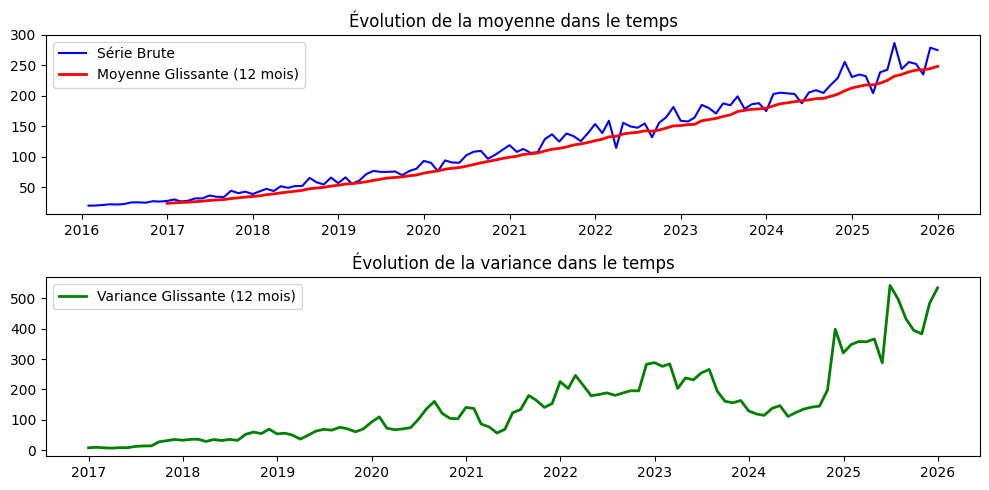

In [10]:
# Vérifier si la série est stationnaire:

window_size= 12

# calculer la moyenne et la variance glissante
rolling_mean = df['Ventes'].rolling(window= window_size).mean()
rolling_var = df["Ventes"].rolling(window= window_size).var()



# Visualisation pour vérifer si la moyenne et la variance sont constantes

plt.figure(figsize=(10,5))
plt.subplot(2, 1, 1)
plt.plot(df['Ventes'], label='Série Brute', color='blue')
plt.plot(rolling_mean, label='Moyenne Glissante (12 mois)', color='red', linewidth=2)
plt.legend()
plt.title("Évolution de la moyenne dans le temps")

plt.subplot(2, 1, 2)
plt.plot(rolling_var, label='Variance Glissante (12 mois)', color='green', linewidth=2)
plt.legend()
plt.title("Évolution de la variance dans le temps")

plt.tight_layout()
plt.show()

<b> Donc la série n'est pas stationnaire

### Méthode 2: Le test ADF

### Test ADF

- Hypothèse nulle (H_0) : La série est non-stationnaire (elle possède une racine unitaire, c'est-à-dire une tendance).

- Hypothèse alternative (H_1) : La série est stationnaire.

- Règle de décision :On regarde la p-value. Si p-value < 0.05, on rejette l'hypothèse nulle (H_0).

- Conclusion : La série est stationnaire ! Si p-value > 0.05, on ne peut pas rejeter H_0, la série n'est donc pas stationnaire.

In [11]:
result_brut = adfuller(df['Ventes'])

print("Test ADF sur la série brute est : ")
print(result_brut, "\n")

print(f"p_value est : {result_brut[1]}")
# On a la p_value = 1 > 0.5 Donc on garde H0 --> La série n'est pas stationnaire


Test ADF sur la série brute est : 
(3.197376370370399, 1.0, 6, 113, {'1%': -3.489589552580676, '5%': -2.887477210140433, '10%': -2.580604145195395}, 802.2991004347575) 

p_value est : 1.0


C:\Users\hp\AppData\Local\Temp\ipykernel_10812\237456877.py:1: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result_brut = adfuller(df['Ventes'])


### Pour rendre la série stationnaire, on va appliquer la transformation Box-Cox pour stabiliser la variance

In [ ]:
series_boxcox, lmbda = boxcox(df["Ventes"])  # lambda choisit par l'algorithme
print(f"lambda: {lmbda} \n {series_boxcox}")

lambda: 0.403981888421173 
 [ 5.84003964  5.87074879  6.00636654  6.20247423  6.13979502  6.25476739
  6.66110519  6.68299054  6.59315504  6.94190884  6.86554479  7.00524032
  7.33142928  6.87841774  7.06231503  7.55660205  7.55962765  8.13374704
  7.88208782  7.84571438  8.99453971  8.57118854  8.83197394  8.40515133
  8.90284642  9.31167583  8.94736784  9.72472544  9.47284703  9.75267489
  9.76601089 10.9427669  10.31951721  9.99104065 10.98384016 10.1951981
 11.01039106 10.09977629 10.55914028 11.44223329 11.83987621 11.71777813
 11.72070777 11.76927793 11.29693991 11.8323562  12.1030861  12.99840813
 12.78756956 11.80078546 13.05314109 12.81971906 12.79615375 13.60917464
 13.95852737 14.04369256 13.22998713 13.65336433 14.13061915 14.60241147
 13.94669038 14.23871024 13.84064746 13.91266193 15.17005476 15.58889402
 14.93700952 15.6578292  15.43175044 14.97873832 15.68144598 16.45363052
 15.70153674 16.7195654  14.33874967 16.55786295 16.2586809  16.15104194
 16.5015068  15.33275586

### Ensuite, on applique la différenciation pour supprimer la tendance


In [13]:
series_diff = pd.Series(series_boxcox, index=df.index).diff().dropna()
series_diff

2016-02-29    0.030709
2016-03-31    0.135618
2016-04-30    0.196108
2016-05-31   -0.062679
2016-06-30    0.114972
                ...   
2025-08-31    0.423201
2025-09-30   -0.112434
2025-10-31   -0.652283
2025-11-30    1.609265
2025-12-31   -0.141040
Freq: ME, Length: 119, dtype: float64

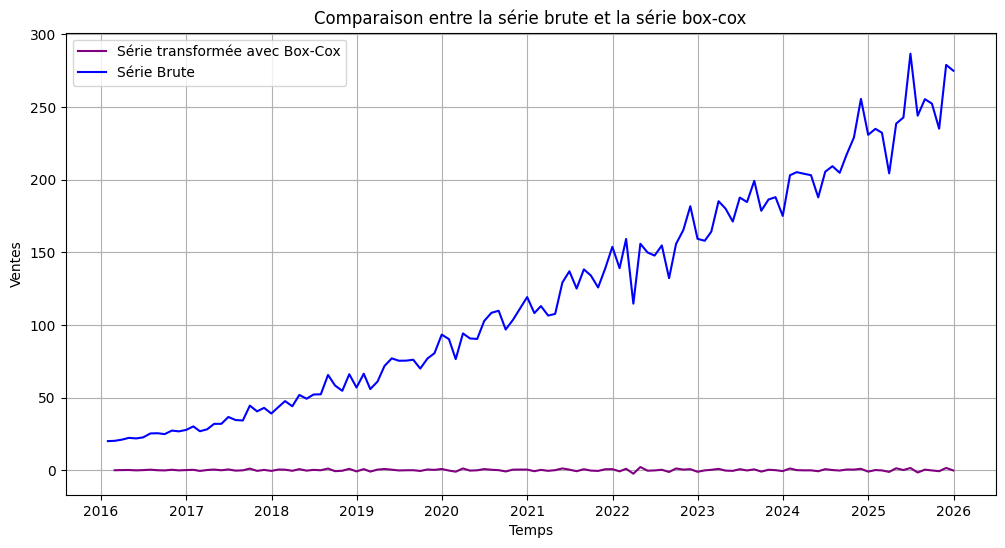

In [14]:

plt.figure(figsize=(12,6))
plt.plot(series_diff.index, series_diff, color="purple", label="Série transformée avec Box-Cox")
plt.plot(df.index, df['Ventes'], color="blue", label="Série Brute")

plt.title("Comparaison entre la série brute et la série box-cox")
plt.xlabel("Temps")
plt.ylabel("Ventes")
plt.legend()
plt.grid(True)
plt.show()

In [15]:
# On vérifie si la série est devenue stationnaire

result_brut = adfuller(series_diff)

print("Test ADF sur la série avec transformation BoxCox et différenciation est : ")
print(result_brut, "\n")

print(f"p_value est : {result_brut[1]}") 
# La p_value est inférieur à 0.5 donc on rejete H0 er la série est stationnaire

Test ADF sur la série avec transformation BoxCox et différenciation est : 
(-8.834821477695108, 1.7305271073777828e-14, 5, 113, {'1%': -3.489589552580676, '5%': -2.887477210140433, '10%': -2.580604145195395}, 169.91684766757058) 

p_value est : 1.7305271073777828e-14


C:\Users\hp\AppData\Local\Temp\ipykernel_10812\3761455322.py:3: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result_brut = adfuller(series_diff)


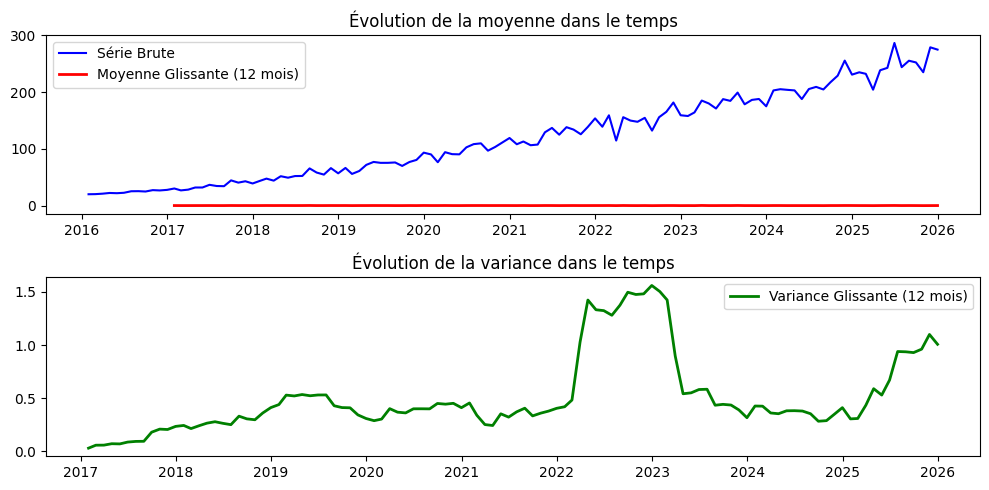

In [16]:
# Vérifier si la série est devenue stationnaire:

window_size= 12

rolling_mean = series_diff.rolling(window= window_size).mean()
rolling_var = series_diff.rolling(window= window_size).var()


plt.figure(figsize=(10,5))
plt.subplot(2, 1, 1)
plt.plot(df['Ventes'], label='Série Brute', color='blue')
plt.plot(rolling_mean, label='Moyenne Glissante (12 mois)', color='red', linewidth=2)
plt.legend()
plt.title("Évolution de la moyenne dans le temps")

plt.subplot(2, 1, 2)
plt.plot(rolling_var, label='Variance Glissante (12 mois)', color='green', linewidth=2)
plt.legend()
plt.title("Évolution de la variance dans le temps")

plt.tight_layout()
plt.show()

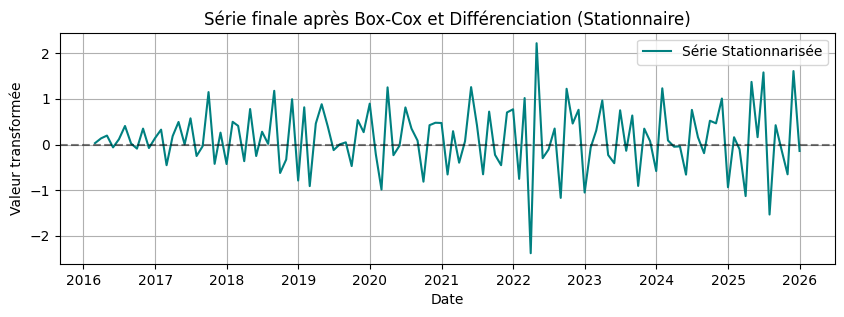

In [17]:
plt.figure(figsize=(10, 3))
plt.plot(series_diff.index, series_diff, color="teal", label="Série Stationnarisée")
plt.axhline(0, color="black", linestyle="--", alpha=0.5)
plt.title("Série finale après Box-Cox et Différenciation (Stationnaire)")
plt.xlabel("Date")
plt.ylabel("Valeur transformée")
plt.legend()
plt.grid(True)
plt.show()